# Preprocessing plotting

## Plotting ICA effects on baseline and post-patching

session
Baseline         2.157895
Post-patching    2.592105
Name: excluded, dtype: float64


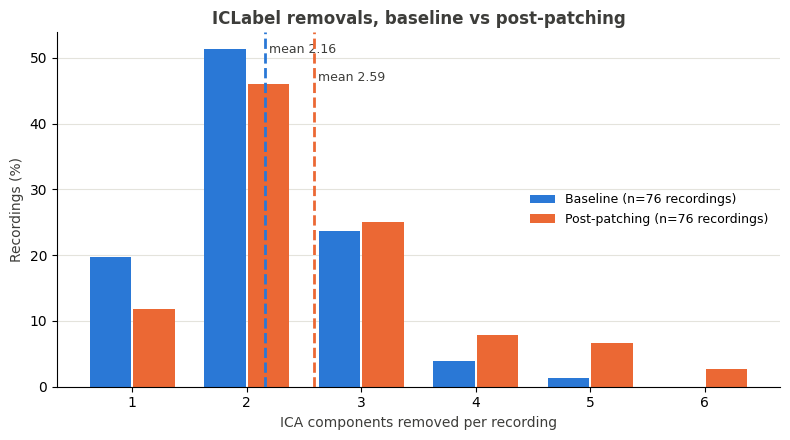

In [15]:
from core import settings
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
from core import plotting

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

SESSION_COLORS = {"Baseline": "#2a78d6", "Post-patching": "#eb6834"}  # same colours as the reaction-time plots
TEXT_COLOR, GRID_COLOR = "#3d3d3a", "#e4e3dc"

ica_pd = pd.read_csv(settings.QC_DIR/"ica_report.csv")

parts = ica_pd["recording"].str.split("\\")


ica_pd["subject"] = parts.str[-4]
ica_pd["session"] = parts.str[-3]
ica_pd["rec"] = parts.str[-2]

per_rec = ica_pd.groupby(["subject", "session", "rec"])["excluded"].sum()
per_cond = per_rec.groupby("session").mean()
print(per_cond)

counts = per_rec.rename("n_removed").reset_index()
values = np.arange(counts["n_removed"].min(), counts["n_removed"].max() + 1)



width = 0.38

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (session, color) in enumerate(SESSION_COLORS.items()):
    s = counts.loc[counts["session"] == session, "n_removed"]
    share = s.value_counts(normalize=True).reindex(values, fill_value=0) * 100
    ax.bar(values + (i - 0.5) * width, share, width=width * 0.95, color=color,
           label=f"{session} (n={len(s)} recordings)", zorder=2)
    ax.axvline(s.mean(), color=color, linestyle="--", linewidth=2, zorder=3)
    ax.text(s.mean(), 0.97 - 0.08 * i, f" mean {s.mean():.2f}", transform=ax.get_xaxis_transform(),
            color=TEXT_COLOR, fontsize=9, va="top", ha="left")

ax.set_xticks(values)
ax.set_xlabel("ICA components removed per recording", color=TEXT_COLOR)
ax.set_ylabel("Recordings (%)", color=TEXT_COLOR)
ax.set_title("ICLabel removals, baseline vs post-patching", color=TEXT_COLOR, fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID_COLOR, zorder=0)
ax.legend(frameon=False, fontsize=9, loc="center right")


plotting.save_button(fig, save_dir=settings.PLOT_DIR / "qc", default_name="ica_removals_distribution")
plt.tight_layout()
plt.show()


## Preprocessing effects table: baseline vs post-patching

One row per preprocessing step: the value of each session (means over subjects unless stated) and a paired t-test over the subjects, each represented by their mean per session. Reads `auto_bad_chans.csv` and `qc_subjects.csv` of `settings.QC_DIR` (fast-press counts from `fast_press_report.csv` for builds whose `qc_subjects.csv` lacks them) and saves `preproc_effects_table.csv` next to them.

In [ ]:
# Effect of every preprocessing step, baseline vs post-patching: one value per session (means over subjects unless stated)
# and a paired t-test over the subjects' values. Reads the QC reports of settings.QC_DIR written by make_dataset.py.
from scipy.stats import ttest_rel

SESSIONS = ["Baseline", "Post-patching"]
MODEL_EGI = set(settings.EGI_TO_1020_MAP)  # EGI names of the model channels (Cz, the recording reference, is not checked by the detector)
N_MODEL = settings.N_CHANNELS


def paired_p(wide):
    """Paired t-test p over the subjects of wide (index subject, columns SESSIONS); subjects missing a session are left out."""
    wide = wide[SESSIONS].dropna()
    if (wide[SESSIONS[1]] - wide[SESSIONS[0]]).ne(0).sum() < 2:
        return np.nan
    return ttest_rel(wide[SESSIONS[0]], wide[SESSIONS[1]]).pvalue


def fmt(value, digits=2, suffix=""):
    return "—" if value is None or (isinstance(value, float) and np.isnan(value)) else f"{value:.{digits}f}{suffix}"


def fmt_p(p):
    return "—" if p is None or np.isnan(p) else (f"{p:.3f}" if p >= 0.001 else f"{p:.1e}")


rows = []
def add(step, measure, baseline, post, p=np.nan):
    rows.append({"step": step, "measure": measure, "Baseline": baseline, "Post-patching": post, "p (paired t-test)": fmt_p(p)})


# ---- automatic bad channel detection: one row per channel x recording in auto_bad_chans.csv
bad = pd.read_csv(settings.QC_DIR / "auto_bad_chans.csv")
parts = bad["recording"].str.replace("\\", "/", regex=False).str.split("/")
bad["subject"], bad["session"] = parts.str[-4], parts.str[-3]
reasons = bad["reasons"].fillna("")
bad["flagged"] = reasons.str.len() > 0
bad["model_flagged"] = bad["flagged"] & bad["channel"].isin(MODEL_EGI)
bad["clipping"] = reasons.str.contains("clip")
bad["noisy"] = reasons.str.contains("nois")
per_recording = bad.groupby(["subject", "session", "recording"]).agg(
    checks=("flagged", "size"), flagged=("flagged", "sum"), model_flagged=("model_flagged", "sum"),
    clipping=("clipping", "sum"), noisy=("noisy", "sum"))
per_subject = per_recording.groupby(["subject", "session"]).mean()
per_subject["checks_flagged_pct"] = 100 * per_subject["flagged"] / per_subject["checks"]


def bad_wide(column):
    return per_subject[column].unstack("session")


for column, measure in [("checks_flagged_pct", "Channel checks flagged (%)"),
                        ("flagged", "Flagged channels per recording (mean)"),
                        ("model_flagged", "Flagged model channels per recording (mean)")]:
    wide = bad_wide(column)
    add("Automatic bad channels", measure, fmt(wide[SESSIONS[0]].mean()), fmt(wide[SESSIONS[1]].mean()), paired_p(wide))
clip, noisy = bad_wide("clipping"), bad_wide("noisy")
add("Automatic bad channels", "Reasons (flags per recording, mean)",
    f"clipping {fmt(clip[SESSIONS[0]].mean())}, noisy {fmt(noisy[SESSIONS[0]].mean())}",
    f"clipping {fmt(clip[SESSIONS[1]].mean())}, noisy {fmt(noisy[SESSIONS[1]].mean())}",
    np.nan)
rows[-1]["p (paired t-test)"] = f"clipping {fmt_p(paired_p(clip))}, noisy {fmt_p(paired_p(noisy))}"

# ---- per subject x session QC table (ICA, autoreject, fast presses, final dataset)
qc = pd.read_csv(settings.QC_DIR / "qc_subjects.csv")
qc = qc[qc["session"].isin(SESSIONS)].copy()
qc["after_autoreject"] = qc["epochs before autoreject"] - qc["autoreject dropped"]
if "fast-press dropped" not in qc.columns:  # older builds: take the fast-press counts from their own report, if there is one
    fast_press_path = settings.QC_DIR / "fast_press_report.csv"
    if fast_press_path.exists():
        fast = pd.read_csv(fast_press_path).groupby(["subject", "session"])["n_dropped"].sum().rename("fast-press dropped")
        qc = qc.merge(fast.reset_index(), on=["subject", "session"], how="left")


def wide(column):
    return qc.pivot(index="subject", columns="session", values=column)


def mean_row(step, measure, column, digits=2, scale=1.0):
    w = wide(column) * scale
    add(step, measure, fmt(w[SESSIONS[0]].mean(), digits), fmt(w[SESSIONS[1]].mean(), digits), paired_p(w))


mean_row("ICA (ICLabel)", "Components removed per recording (mean)", "ICA components removed per recording")
classes = {"eye": "ICA removed: eye", "muscle": "ICA removed: muscle", "other": "ICA removed: other classes"}
class_wide = {name: wide(column) for name, column in classes.items()}
add("ICA (ICLabel)", "Removed by class (per session, mean)",
    ", ".join(f"{name} {fmt(w[SESSIONS[0]].mean())}" for name, w in class_wide.items()),
    ", ".join(f"{name} {fmt(w[SESSIONS[1]].mean())}" for name, w in class_wide.items()))
rows[-1]["p (paired t-test)"] = ", ".join(f"{name} {fmt_p(paired_p(w))}" for name, w in class_wide.items())

before, dropped = wide("epochs before autoreject"), wide("autoreject dropped")
add("Autoreject", "Epochs dropped (% of all)",
    fmt(100 * dropped[SESSIONS[0]].sum() / before[SESSIONS[0]].sum(), suffix="%"),
    fmt(100 * dropped[SESSIONS[1]].sum() / before[SESSIONS[1]].sum(), suffix="%"),
    paired_p(wide("autoreject dropped (%)")))
dropped_pct = wide("autoreject dropped (%)")
add("Autoreject", "Sessions with > 20% dropped", str(int((dropped_pct[SESSIONS[0]] > 20).sum())), str(int((dropped_pct[SESSIONS[1]] > 20).sum())))
mean_row("Autoreject", "Epochs per subject after autoreject (mean)", "after_autoreject", digits=1)
mean_row("Autoreject", "Interpolated channels per kept epoch, all 65 (mean)", "autoreject repaired channels per kept epoch (all 65)")
mean_row("Autoreject", "Interpolated model channels per kept epoch (mean)", "autoreject repaired model channels per kept epoch")

if "fast-press dropped" in qc.columns:
    fast_dropped = wide("fast-press dropped")
    after = wide("after_autoreject")
    add("Fast-press exclusion (< 500 ms)", "Epochs dropped (% of all)",
        fmt(100 * fast_dropped[SESSIONS[0]].sum() / after[SESSIONS[0]].sum(), suffix="%"),
        fmt(100 * fast_dropped[SESSIONS[1]].sum() / after[SESSIONS[1]].sum(), suffix="%"),
        paired_p(100 * fast_dropped / after))  # per-subject drop share
else:
    print("No fast-press counts in this build's QC reports: the fast-press row is left out")

kept = wide("kept epochs")
add("Final dataset", "Epochs kept (total)", f"{int(kept[SESSIONS[0]].sum()):,}".replace(",", " "), f"{int(kept[SESSIONS[1]].sum()):,}".replace(",", " "))
add("Final dataset", "Per subject (median / min)", f"{kept[SESSIONS[0]].median():.0f} / {kept[SESSIONS[0]].min():.0f}",
    f"{kept[SESSIONS[1]].median():.0f} / {kept[SESSIONS[1]].min():.0f}", paired_p(kept))
masked = wide("masked trial x model channel pairs (%)") * N_MODEL / 100  # model channels masked per epoch, any reason
add("Final dataset", "Model channels masked per epoch, any reason (mean)", fmt(masked[SESSIONS[0]].mean()), fmt(masked[SESSIONS[1]].mean()), paired_p(masked))

preproc_table = pd.DataFrame(rows)
n_subjects = qc["subject"].nunique()
print(f"Preprocessing effects, {n_subjects} subjects. p: paired t-test over the subjects (one mean per subject and session);"
      f" model channels: the {N_MODEL} channels used by the models ({bad.loc[bad['channel'].isin(MODEL_EGI), 'channel'].nunique()} checked by the bad channel detector)")
display(preproc_table)
preproc_table.to_csv(settings.QC_DIR / "preproc_effects_table.csv", index=False)
print(f"Saved to {settings.QC_DIR / 'preproc_effects_table.csv'}")